
# Individuell uppgift – Hälsostudie
## Del 1 – Grundläggande analys och statistik

### 1. Introduktion

Syftet med denna analys är att undersöka data från en hälsostudie med hjälp av Python och statistiska metoder.

Datasetet innehåller information om deltagarnas ålder, kön, längd, vikt, systoliskt blodtryck, kolesterolnivå, rökvanor och förekomst av sjukdom.

I analysen kommer jag att:
- Beräkna beskrivande statistik.
- Visualisera data med olika diagram.
- Simulera sjukdomsförekomst.
- Beräkna och jämföra konfidensintervall.
- Undersöka om rökare har högre genomsnittligt blodtryck än icke-rökare.
- Diskutera resultaten och metodernas begränsningar.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Samma slumpmässiga resultat vid varje körning
np.random.seed(42)

# Läs in hälsostudiens data
df = pd.read_csv("../data/health_study_dataset.csv")

# Visa datasetets storlek
print("Antal rader och kolumner:", df.shape)

# Visa de första fem raderna
display(df.head())


Antal rader och kolumner: (800, 9)


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


## 2. Beskrivande statistik

För att få en överblick över deltagarna i hälsostudien beräknas medelvärde, median, minsta värde och största värde för följande variabler:

- Ålder (`age`)
- Vikt (`weight`)
- Längd (`height`)
- Systoliskt blodtryck (`systolic_bp`)
- Kolesterolnivå (`cholesterol`)

Beräkningarna genomförs med hjälp av Python och biblioteket pandas.

In [3]:
# 2. Beskrivande statistik
# Beräkna medelvärde, median, min och max

kolumner = ["age", "weight", "height", "systolic_bp", "cholesterol"]

statistik = df[kolumner].agg(["mean", "median", "min", "max"])

# Ändra till svenska benämningar
statistik = statistik.rename(index={
    "mean": "Medelvärde",
    "median": "Median",
    "min": "Min",
    "max": "Max"})

# Visa tabellen med två decimaler
display(statistik.round(2))

,age,weight,height,systolic_bp,cholesterol
Medelvärde,49.43,73.41,171.85,149.18,4.93
Median,50.00,73.20,171.35,149.40,4.97
Min,18.00,33.70,144.40,106.80,2.50
Max,90.00,114.40,200.40,185.90,7.88


### Resultat och tolkning

Hälsostudien omfattar 800 deltagare. Medelåldern är 49,43 år och medianåldern är 50 år. Deltagarnas ålder varierar mellan 18 och 90 år.

Medelvikten är 73,41 kg och medellängden är 171,85 cm. Det genomsnittliga systoliska blodtrycket är 149,18 mmHg och kolesterolnivån är i genomsnitt 4,93 mmol/L.

Resultaten ger en första överblick över deltagarnas hälsodata. För att undersöka fördelningar, skillnader och eventuella avvikande värden analyseras data vidare med hjälp av diagram.

## 3. Visualisering av data

För att undersöka hur deltagarnas hälsodata är fördelade används tre olika diagram:

1. **Histogram över systoliskt blodtryck:** Visar hur blodtrycksvärdena är fördelade bland deltagarna.
2. **Låddiagram över vikt per kön:** Jämför viktens median, spridning och eventuella extremvärden mellan kvinnor och män.
3. **Stapeldiagram över andelen rökare:** Visar hur stor andel av deltagarna som röker respektive inte röker.

Diagrammen används för att upptäcka mönster, skillnader och eventuella avvikande värden i datasetet.

### 3.1 Histogram över systoliskt blodtryck

Ett histogram används för att visa hur deltagarnas systoliska blodtryck är fördelat. Diagrammet visar hur många deltagare som har blodtryck inom olika intervall, vilket gör det möjligt att undersöka spridningen och upptäcka eventuella avvikande värden.

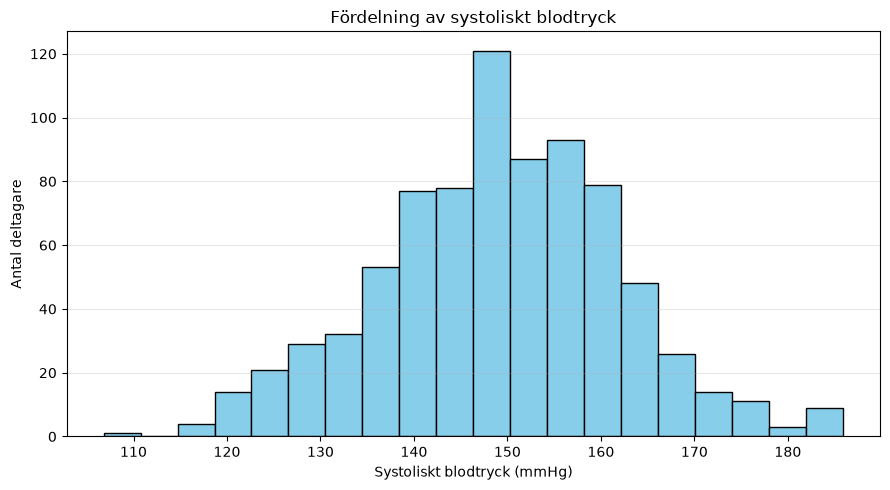

In [4]:
# 3.1 Histogram över systoliskt blodtryck

plt.figure(figsize=(9, 5))

# Skapa histogram över blodtryck
plt.hist(
    df["systolic_bp"].dropna(),
    bins=20,
    color="skyblue",
    edgecolor="black")

# Rubrik och axelbeskrivningar
plt.title("Fördelning av systoliskt blodtryck")
plt.xlabel("Systoliskt blodtryck (mmHg)")
plt.ylabel("Antal deltagare")

# Gör diagrammet tydligare
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Visa diagrammet
plt.show()

#### Resultat och tolkning

Histogrammet visar hur det systoliska blodtrycket är fördelat bland deltagarna i hälsostudien.

De flesta deltagarna har ett systoliskt blodtryck mellan cirka 135 och 165 mmHg. Flest observationer finns omkring 150 mmHg.

Fördelningen är ungefär klockformad, med färre deltagare vid de lägsta och högsta blodtrycksvärdena.

Det genomsnittliga systoliska blodtrycket är 149,18 mmHg, vilket stämmer väl överens med den koncentration av värden som syns i histogrammet.

### 3.2 Låddiagram över vikt per kön

Ett låddiagram används för att jämföra viktfördelningen mellan kvinnor och män i hälsostudien.

Diagrammet visar median, spridning och eventuella avvikande värden. Syftet är att undersöka om det finns skillnader i deltagarnas vikt mellan de två grupperna.

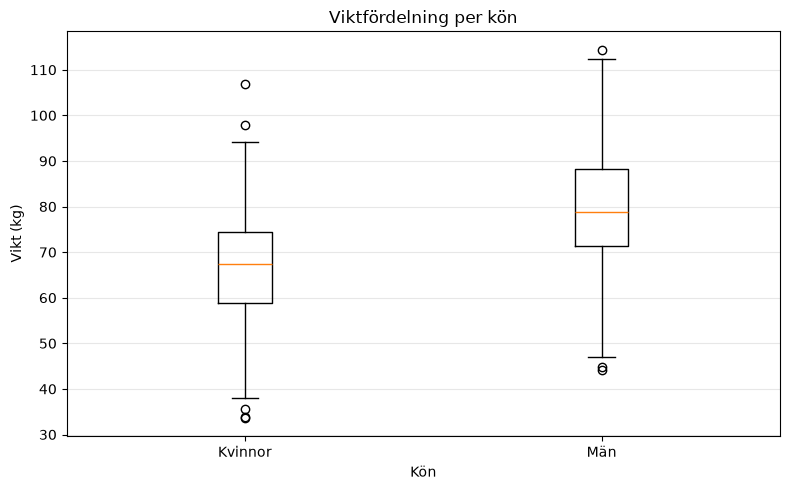

In [5]:
# 3.2 Låddiagram över vikt per kön

# Dela upp deltagarnas vikt efter kön
vikt_kvinnor = df.loc[df["sex"] == "F", "weight"].dropna()
vikt_man = df.loc[df["sex"] == "M", "weight"].dropna()

# Skapa låddiagrammet
plt.figure(figsize=(8, 5))

plt.boxplot(
    [vikt_kvinnor, vikt_man],
    tick_labels=["Kvinnor", "Män"])

# Rubrik och axelbeskrivningar
plt.title("Viktfördelning per kön")
plt.xlabel("Kön")
plt.ylabel("Vikt (kg)")

# Gör diagrammet tydligare
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Visa diagrammet
plt.show()

#### Resultat och tolkning

Låddiagrammet visar viktfördelningen för kvinnor och män i hälsostudien.

Medianvikten för kvinnor är ungefär 67 kg, medan medianvikten för män är cirka 79 kg. Det innebär att männen generellt har en högre vikt än kvinnorna i detta dataset.

Diagrammet visar även en viss spridning inom båda grupperna. Det finns några avvikande värden, både bland deltagare med låg vikt och bland deltagare med hög vikt.

Resultatet visar att det finns skillnader i viktfördelningen mellan kvinnor och män i hälsostudien. Diagrammet visar däremot inte vad skillnaderna beror på.

### 3.3 Stapeldiagram över andelen rökare

Ett stapeldiagram används för att visa hur stor andel av deltagarna i hälsostudien som röker respektive inte röker.

Syftet är att jämföra de två grupperna och undersöka hur vanligt förekommande rökning är bland deltagarna.

Andelarna beräknas i procent för att göra resultatet lättare att tolka.

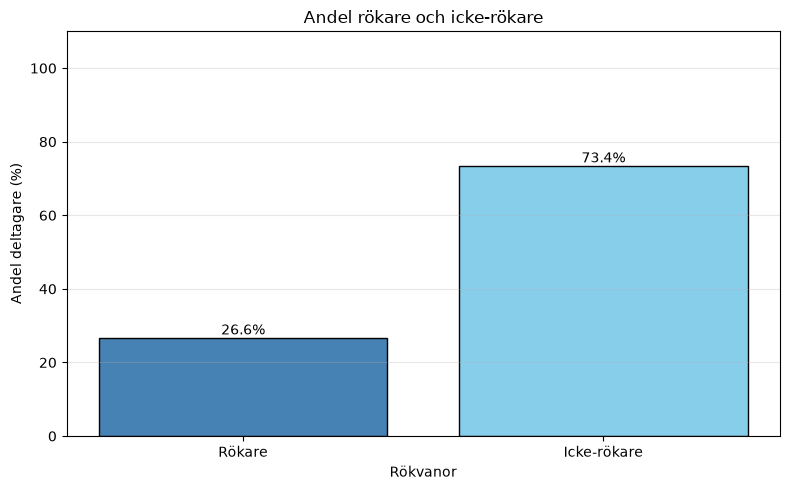

Andel rökare: 26.62 %
Andel icke-rökare: 73.38 %


In [6]:
# 3.3 Stapeldiagram över andelen rökare

# Beräkna andelen rökare och icke-rökare i procent
andel_rokare = df["smoker"].value_counts(normalize=True) * 100

# Bestäm ordningen på staplarna
andel_rokare = andel_rokare.reindex(["Yes", "No"], fill_value=0)

# Svenska benämningar
grupper = ["Rökare", "Icke-rökare"]

# Skapa stapeldiagrammet
plt.figure(figsize=(8, 5))

staplar = plt.bar(
    grupper,
    andel_rokare.values,
    color=["steelblue", "skyblue"],
    edgecolor="black")

# Rubrik och axelbeskrivningar
plt.title("Andel rökare och icke-rökare")
plt.xlabel("Rökvanor")
plt.ylabel("Andel deltagare (%)")

# Visa procent ovanför varje stapel
for stapel in staplar:
    hojd = stapel.get_height()
    plt.text(
        stapel.get_x() + stapel.get_width() / 2,
        hojd + 1,
        f"{hojd:.1f}%",
        ha="center")

# Gör diagrammet tydligare
plt.ylim(0, 110)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Visa diagrammet
plt.show()

# Skriv ut andelarna
print("Andel rökare:", round(andel_rokare["Yes"], 2), "%")
print("Andel icke-rökare:", round(andel_rokare["No"], 2), "%")

#### Resultat och tolkning

Stapeldiagrammet visar att 26,62 % av deltagarna i hälsostudien är rökare, medan 73,38 % är icke-rökare.

Det innebär att ungefär var fjärde deltagare röker och att majoriteten av deltagarna inte röker.

Resultatet visar hur rökvanorna är fördelade i datasetet. Diagrammet visar däremot inte om rökning har något samband med deltagarnas blodtryck eller sjukdomsförekomst. För att undersöka sådana samband krävs ytterligare analyser.

## 4. Simulering av sjukdomsförekomst

Syftet med simuleringen är att undersöka hur slumpmässig variation kan påverka andelen personer med sjukdom.

I datasetet används variabeln `disease`, där:

- **1** betyder att deltagaren har sjukdomen.
- **0** betyder att deltagaren inte har sjukdomen.

Först beräknas den observerade andelen deltagare med sjukdom i hälsostudien.

Därefter används NumPy för att simulera 1 000 personer, där varje person har samma sannolikhet för sjukdom som den observerade andelen i datasetet.

Slutligen jämförs den simulerade andelen med den observerade andelen för att undersöka hur resultaten kan skilja sig åt på grund av slumpen.

In [7]:
# 4. Simulering av sjukdomsförekomst

# Beräkna andelen deltagare som har sjukdomen
verklig_andel = df["disease"].mean()

# Visa den observerade andelen i procent
print(f"Observerad andel med sjukdom: {verklig_andel * 100:.2f} %")

# Sätt slumpfrö för att få samma resultat vid varje körning
np.random.seed(42)

# Simulera 1000 personer med samma sannolikhet för sjukdom
simulering = np.random.binomial(
    n=1,
    p=verklig_andel,
    size=1000)

# Beräkna den simulerade andelen
simulerad_andel = simulering.mean()

# Visa resultatet
print(f"Simulerad andel med sjukdom: {simulerad_andel * 100:.2f} %")

# Beräkna skillnaden i procentenheter
skillnad = (simulerad_andel - verklig_andel) * 100

print(f"Skillnad: {skillnad:.2f} procentenheter")

Observerad andel med sjukdom: 5.88 %
Simulerad andel med sjukdom: 5.60 %
Skillnad: -0.27 procentenheter


### Resultat och tolkning

Den observerade andelen deltagare med sjukdom i hälsostudien är 5,88 %.

Med hjälp av NumPy simulerades 1 000 personer med samma sannolikhet för sjukdom som i det ursprungliga datasetet. Simuleringen gav en sjukdomsandel på 5,60 %.

Skillnaden mellan den simulerade och observerade andelen är cirka −0,27 procentenheter.

Resultatet visar att den simulerade andelen ligger nära den observerade andelen, men att en viss skillnad kan uppstå på grund av slumpmässig variation.

Genom att använda `np.random.seed(42)` blir simuleringen reproducerbar, vilket innebär att samma resultat kan återskapas när koden körs igen med samma inställningar.

**Slutsats:** Simuleringen visar hur slumpen kan påverka resultatet även när sannolikheten för sjukdom är densamma.

## 5. Konfidensintervall för systoliskt blodtryck

Syftet är att beräkna ett 95-procentigt konfidensintervall för medelvärdet av systoliskt blodtryck (`systolic_bp`) i hälsostudien.

Ett konfidensintervall används för att uppskatta populationsmedelvärdet och visa osäkerheten i skattningen.

Beräkningen genomförs med normalapproximation och bygger på stickprovets medelvärde, standardavvikelse, antal observationer och standardfel.

In [8]:
# 5. Konfidensintervall för systoliskt blodtryck

# Hämta blodtrycksvärden och ta bort eventuella saknade värden
blodtryck = df["systolic_bp"].dropna()

# Beräkna antal observationer, medelvärde och standardavvikelse
n = len(blodtryck)
medelvarde = blodtryck.mean()
standardavvikelse = blodtryck.std(ddof=1)

# Beräkna standardfelet
standardfel = standardavvikelse / np.sqrt(n)

# Kritiskt z-värde för 95 % konfidensgrad
z = 1.96

# Beräkna nedre och övre gränsen
nedre_grans = medelvarde - z * standardfel
ovre_grans = medelvarde + z * standardfel

# Visa resultatet
print(f"Antal observationer: {n}")
print(f"Medelvärde: {medelvarde:.2f} mmHg")
print(f"Standardavvikelse: {standardavvikelse:.2f} mmHg")
print(f"Standardfel: {standardfel:.2f} mmHg")
print(f"95 % konfidensintervall: [{nedre_grans:.2f}, {ovre_grans:.2f}] mmHg")

Antal observationer: 800
Medelvärde: 149.18 mmHg
Standardavvikelse: 12.79 mmHg
Standardfel: 0.45 mmHg
95 % konfidensintervall: [148.29, 150.07] mmHg


### Resultat och tolkning

Hälsostudien omfattar 800 observationer av systoliskt blodtryck. Det genomsnittliga blodtrycket är 149,18 mmHg och standardavvikelsen är 12,79 mmHg.

Med hjälp av normalapproximation har ett 95-procentigt konfidensintervall beräknats till **148,29–150,07 mmHg**.

Konfidensintervallet ger ett uppskattat intervall för populationens genomsnittliga systoliska blodtryck.

Ett 95-procentigt konfidensintervall innebär att om samma metod används på många upprepade stickprov, kommer ungefär 95 % av de beräknade intervallen att innehålla populationens verkliga medelvärde.

**Slutsats:** Resultatet visar att det uppskattade genomsnittliga systoliska blodtrycket är cirka 149 mmHg, med en relativt liten osäkerhet i skattningen.

## 6. Hypotesprövning – blodtryck hos rökare och icke-rökare

Syftet med hypotesprövningen är att undersöka om rökare har ett högre genomsnittligt systoliskt blodtryck än icke-rökare i hälsostudien.

Följande hypoteser testas:

- **Nollhypotes (H₀):** Rökare har inte högre genomsnittligt systoliskt blodtryck än icke-rökare.
- **Alternativhypotes (H₁):** Rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare.

För att jämföra gruppernas medelvärden används ett ensidigt Welch t-test med signifikansnivån 5 % (α = 0,05).

Om p-värdet är mindre än 0,05 förkastas nollhypotesen. Annars kan nollhypotesen inte förkastas.

In [9]:
# 6. Hypotesprövning – rökare och icke-rökare

from scipy.stats import ttest_ind

# Hämta blodtrycksvärden för respektive grupp
rokare = df.loc[df["smoker"] == "Yes", "systolic_bp"].dropna()
icke_rokare = df.loc[df["smoker"] == "No", "systolic_bp"].dropna()

# Beräkna gruppernas storlek och medelvärde
print(f"Antal rökare: {len(rokare)}")
print(f"Antal icke-rökare: {len(icke_rokare)}")

print(f"Medelblodtryck för rökare: {rokare.mean():.2f} mmHg")
print(f"Medelblodtryck för icke-rökare: {icke_rokare.mean():.2f} mmHg")

# Utför ett ensidigt Welch t-test
t_statistik, p_varde = ttest_ind(
    rokare,
    icke_rokare,
    equal_var=False,
    alternative="greater")

# Visa testresultat
print(f"t-värde: {t_statistik:.4f}")
print(f"p-värde: {p_varde:.4f}")

# Tolka resultatet utifrån signifikansnivån 0,05
if p_varde < 0.05:
    print("Resultat: Nollhypotesen förkastas.")
    print("Det finns statistiskt stöd för att rökare har högre medelblodtryck.")
else:
    print("Resultat: Nollhypotesen kan inte förkastas.")
    print("Det finns inte tillräckligt statistiskt stöd för att rökare har högre medelblodtryck.")

Antal rökare: 213
Antal icke-rökare: 587
Medelblodtryck för rökare: 149.52 mmHg
Medelblodtryck för icke-rökare: 149.05 mmHg
t-värde: 0.4503
p-värde: 0.3264
Resultat: Nollhypotesen kan inte förkastas.
Det finns inte tillräckligt statistiskt stöd för att rökare har högre medelblodtryck.


### Resultat och tolkning

I hälsostudien ingår 800 deltagare, varav 213 är rökare och 587 är icke-rökare.

Det genomsnittliga systoliska blodtrycket är 149,52 mmHg för rökare och 149,05 mmHg för icke-rökare. Skillnaden mellan grupperna är 0,47 mmHg.

Ett ensidigt Welch t-test genomfördes med signifikansnivån 5 % (0,05). Testet gav ett t-värde på 0,4503 och ett p-värde på 0,3264.

Eftersom p-värdet är större än 0,05 kan nollhypotesen inte förkastas.

**Slutsats:** Resultatet visar en liten skillnad i genomsnittligt blodtryck mellan rökare och icke-rökare, men skillnaden är inte statistiskt signifikant. Det finns därför inte tillräckligt statistiskt stöd för att rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare.